<a href="https://colab.research.google.com/github/BarGinger/Deep_Learning_MEG/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning - Assigment 2

### Group Number: 22

### Teammates:
1. **Mahshid Jafar Tajrishi**
2. **Bar Melinarskiy**
3. **Cis van Aken**
4. **Simon van Klompenburg**

## Imports entire notebook

In [1]:
# Helper function to check if the code is running in Google Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Usage
if is_colab():
    print("Running in Google Colab")
else:
    print("Not running in Google Colab")


# Importing libraries
import pandas as pd
import numpy as np
import Models
import utils as utils
import torch
import matplotlib.pyplot as plt
import os
import random
import datetime
import importlib
importlib.reload(utils)
importlib.reload(Models)

Not running in Google Colab


<module 'Models' (namespace) from ['c:\\Users\\bar24\\OneDrive - Universiteit Utrecht\\Documents\\School\\UU Data Sceince MSc\\1st Year\\Period 4\\Deep learning (INFOMDLR)\\Assignments\\Deep_Learning_MEG\\Models']>

## Global Definitions

In [2]:
# Path to the zip file
data_dir = "./Data"
google_drive_folder = "/content/drive/MyDrive/UU"
zip_path = f"{data_dir}/Final Project data.zip"
output_dir = "./Output"
model_dir = "./Models"

# check if outpiut directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# check if model directory exists
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Set the device to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

debug_mode = False

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# model and data related parameters
scaler_type = utils.NormalizationType.Z_SCORE_LOCAL  # or MINMAX_LOCAL, Z_SCORE_TIMEWISE
which_dataset = "both"  # or "cross"
downsample = True  # or False
downsample_rate = 0  
if downsample:
    downsample_rate = 7

### Check if we have cude

In [3]:
# Check if CUDA is available
print(torch.__version__)
print(torch.version.cuda)  # Should match CUDA 12.5
print(torch.backends.cudnn.version())  # Should return a version, not None
print(torch.cuda.is_available())  # Should return True

2.5.1
None
90100
True


### Load the datasets

In [4]:
train_data_cross, train_df_cross, test_data, test_df = utils.load_dataset(
    which_dataset="cross",  # or "cross", "both"
    data_dir=data_dir,
    scaler_type=scaler_type,
    downsample_rate=downsample_rate
)
print("train_data_cross shape:", train_data_cross.shape)
print("train_df_cross shape:", train_df_cross.shape)
print("test_data shape:", test_data.shape)
print("test_df shape:", test_df.shape)

train_data_intra, train_df_intra, test_data_intra, test_df_intra = utils.load_dataset(
    which_dataset="intra",  # or "cross", "both"
    data_dir=data_dir,
    scaler_type=scaler_type,
    downsample_rate=downsample_rate
)
print("train_data_intra shape:", train_data_intra.shape)
print("train_df_intra shape:", train_df_intra.shape)
print("test_data_intra shape:", test_data_intra.shape)
print("test_df_intra shape:", test_df_intra.shape)

# Concatenate train data and DataFrames
train_data = torch.cat([train_data_cross, train_data_intra], dim=0)
train_df = pd.concat([train_df_cross, train_df_intra], ignore_index=True)
print("Merged train_data shape:", train_data.shape)
print("Merged train_df shape:", train_df.shape)

Loading cross dataset...
Loading cached: Data\Normalized\z_score_local\cross_train_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test1_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test2_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test3_scaled.pt
Data for dataset cross was loaded successfully
train_data_cross shape: torch.Size([64, 248, 5089])
train_df_cross shape: (64, 11)
test_data shape: torch.Size([48, 248, 5089])
test_df shape: (48, 11)
Loading intra dataset...
Loading cached: Data\Normalized\z_score_local\intra_train_scaled.pt
Loading cached: Data\Normalized\z_score_local\intra_test_scaled.pt
Data for dataset intra was loaded successfully
train_data_intra shape: torch.Size([32, 248, 5089])
train_df_intra shape: (32, 11)
test_data_intra shape: torch.Size([8, 248, 5089])
test_df_intra shape: (8, 11)
Merged train_data shape: torch.Size([96, 248, 5089])
Merged train_df shape: (96, 11)


### Definitions for training and logging

In [5]:
# Check if the data is loaded correctly
print("train task types counts:")
print(np.bincount(train_df['task_type'].astype('category').cat.codes))
print("test task types counts:")
print(np.bincount(test_df['task_type'].astype('category').cat.codes))


timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
# Set this once at the top of your notebook/cell
MODEL_NAME = utils.ModelClass.__name__ # "MEGClassifier"
print(f"Using model class: {MODEL_NAME}")
model_name = f"{MODEL_NAME}_{which_dataset}"
model_pth_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.pth"
model_csv_path = f"{output_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.csv"
model_json_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.json"
best_model = None

# create folders if they do not exist
if not os.path.exists(f"{model_dir}/{which_dataset}"):
    os.makedirs(f"{model_dir}/{which_dataset}")


if not os.path.exists(f"{output_dir}/{which_dataset}"):
    os.makedirs(f"{output_dir}/{which_dataset}")

train task types counts:
[24 24 24 24]
test task types counts:
[12 12 12 12]
Using model class: MultiviewAttention


### load the cross dataset best parameters to check with more data (using the Intra train dataset)


In [30]:
import json

json_path = f"{model_dir}/Cross/best_model_MultiviewAttention_cross_20250601_164244.json"
best_params = None


with open(json_path) as f:
    best_params = json.load(f)

best_params["number_channels"] = train_data.shape[1]
best_params["depth"] = 1  # <-- set to 1 for new model
best_params["conv1_filters"] = 128  # <-- set to 1 for new model
best_params["conv2_filters"] = 256  # <-- set to 1 for new model
best_params["number_classes"] = len(np.unique(train_df['task_type']))
best_params["num_classes"] = len(np.unique(train_df['task_type']))
# Recompute split_size if missing
if "split_size" not in best_params:
    T = train_data.shape[2]
    best_params["split_size"] = T // best_params["window_size"]

# Always set mesh_rows and mesh_columns for new model
if "mesh_rows" not in best_params:
    best_params["mesh_rows"] = 8
if "mesh_columns" not in best_params:
    best_params["mesh_columns"] = 31

print("Best parameters loaded:", json.dumps(best_params, indent=4))
best_params["window_size"] = 16

Best parameters loaded: {
    "window_size": 8,
    "conv3_filters": 128,
    "conv1_kernel_shape": [
        3,
        3
    ],
    "conv2_kernel_shape": [
        3,
        3
    ],
    "conv3_kernel_shape": [
        5,
        5
    ],
    "padding1": 1,
    "padding2": 2,
    "padding3": 1,
    "conv1_activation": "gelu",
    "conv2_activation": "relu",
    "conv3_activation": "elu",
    "dense_nodes": 256,
    "dense_activation": "relu",
    "lstm1_cells": 32,
    "lstm2_cells": 128,
    "dense3_nodes": 32,
    "dense3_activation": "relu",
    "learning_rate": 0.0006478504079820903,
    "batch_size": 2,
    "dropout_rate": 0.1,
    "optimizer": "adam",
    "weight_decay": 1.7732690341510755e-05,
    "label_smoothing": 0.15,
    "number_of_heads": 2,
    "number_channels": 248,
    "depth": 1,
    "conv1_filters": 128,
    "conv2_filters": 256,
    "number_classes": 4,
    "num_classes": 4,
    "split_size": 636,
    "mesh_rows": 8,
    "mesh_columns": 31
}


Epoch 1/50 - Acc: 0.4271 - F1: 0.4211 - Loss: 4.6950
Epoch 11/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.5017
Epoch 21/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.5077
Epoch 31/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.5235
Epoch 41/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.5170
Epoch 50/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.5054
Total Train Accuracy: 0.9817


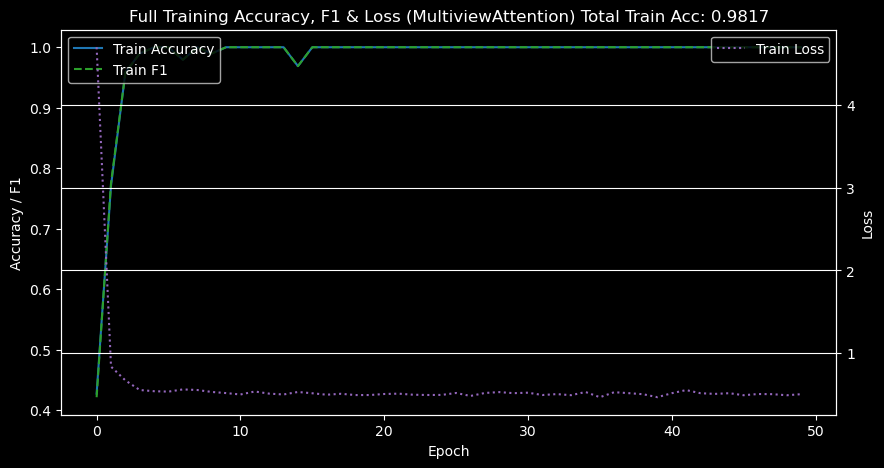

In [33]:
epochs = 50
verbose = True  # Set to False to disable verbose output

# Instantiate model
best_model = utils.ModelClass(**{k: v for k, v in best_params.items() if k in utils.ModelClass.__init__.__code__.co_varnames}).to(device)

# Dataloader
train_loader = utils.get_multiview_dataloader(
        train_data, train_df,
        batch_size=best_params["batch_size"],
        window_size=best_params["window_size"],
        mesh_rows=best_params["mesh_rows"],
        mesh_columns=best_params["mesh_columns"],
        depth=best_params["depth"],
        shuffle=True,
        augment=True
    )

train_accs, train_f1s, train_losses = [], [], []

optimizer_name = best_params.get("optimizer", "adam")
weight_decay = best_params.get("weight_decay", 1e-4)
learning_rate = best_params.get("learning_rate", 0.001)
label_smoothing = best_params.get("label_smoothing", 0.1)

optimizer, scheduler, criterion = utils.get_training_parts(
    best_model, lr=learning_rate, max_epochs=epochs,
    optimizer_name=optimizer_name,
    weight_decay=weight_decay,
    label_smoothing=label_smoothing
)

for epoch in range(epochs):
    train_preds, train_targets, train_loss = utils.single_train_epoch(
        model=best_model, 
        train_loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device
    )
    train_metrics = best_model.evaluate(y_true=train_targets, y_pred=train_preds)
    train_accs.append(train_metrics["overall_accuracy"])
    train_f1s.append(train_metrics["overall_F1"])
    train_losses.append(train_loss)
    scheduler.step()
    if verbose and (epoch % 10 == 0 or epoch == epochs-1):
        print(f"Epoch {epoch+1}/{epochs} - Acc: {train_accs[-1]:.4f} - F1: {train_f1s[-1]:.4f} - Loss: {train_losses[-1]:.4f}")

total_train_acc = np.mean(train_accs)
print(f"Total Train Accuracy: {total_train_acc:.4f}")

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(train_accs, label="Train Accuracy", color='tab:blue')
ax1.plot(train_f1s, label="Train F1", linestyle="--", color='tab:green')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy / F1")
ax1.tick_params(axis='y')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(train_losses, label="Train Loss", linestyle=":", color='tab:purple')
ax2.set_ylabel("Loss")
ax2.tick_params(axis='y')
ax2.legend(loc='upper right')

plt.title(f"Full Training Accuracy, F1 & Loss ({utils.ModelClass.__name__}) Total Train Acc: {total_train_acc:.4f}")
plt.grid(True)
path = f"{output_dir}/{which_dataset}/full_train_{utils.ModelClass.__name__}_{timestamp}.png"
plt.savefig(path, bbox_inches='tight')
plt.show()


#### Saving the final model

In [12]:
# Create the model with the best hyperparameters
torch.save(best_model.state_dict(), model_pth_path)
print(f"Best model saved to {model_pth_path}")

# Save the best hyperparameters to a JSON file
with open(model_json_path, "w") as json_file:
    json.dump(best_params, json_file, indent=4)
print(f"Best hyperparameters saved to {model_json_path}")

Best model saved to ./Models/both/best_model_MultiviewAttention_both_20250601_234504.pth
Best hyperparameters saved to ./Models/both/best_model_MultiviewAttention_both_20250601_234504.json


### Evulate model and save logs

In [34]:
test_csv_path = f"{output_dir}/{which_dataset}/test_metrics_{model_name}_{timestamp}.csv"

test_metrics, df_test_result = utils.evaluate_model_on_testset(
    best_model, test_data, test_df, device,
    batch_size=best_params.get("batch_size", 2),
    input_time_length=best_params.get("input_time_length", 256),
    stride=best_params.get("stride", 256),
    path=test_csv_path
)

print("Test metrics:", test_metrics, '\n')

Test metrics: {'overall_accuracy': 0.8125, 'overall_F1': 0.8038198757763975, 'overall_recall': 0.8125, 'overall_precision': 0.8174169580419581, 'resting_accuracy': 1.0, 'resting_F1': 1.0, 'resting_recall': 1.0, 'resting_precision': 1.0, 'math_accuracy': 0.9166666666666666, 'math_F1': 0.4782608695652174, 'math_recall': 0.4583333333333333, 'math_precision': 0.5, 'memory_accuracy': 0.5, 'memory_F1': 0.2222222222222222, 'memory_recall': 0.16666666666666666, 'memory_precision': 0.3333333333333333, 'motor_accuracy': 0.8333333333333334, 'motor_F1': 0.30303030303030304, 'motor_recall': 0.2777777777777778, 'motor_precision': 0.3333333333333333} 



c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\utils.py:1128: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.05, 1.0))


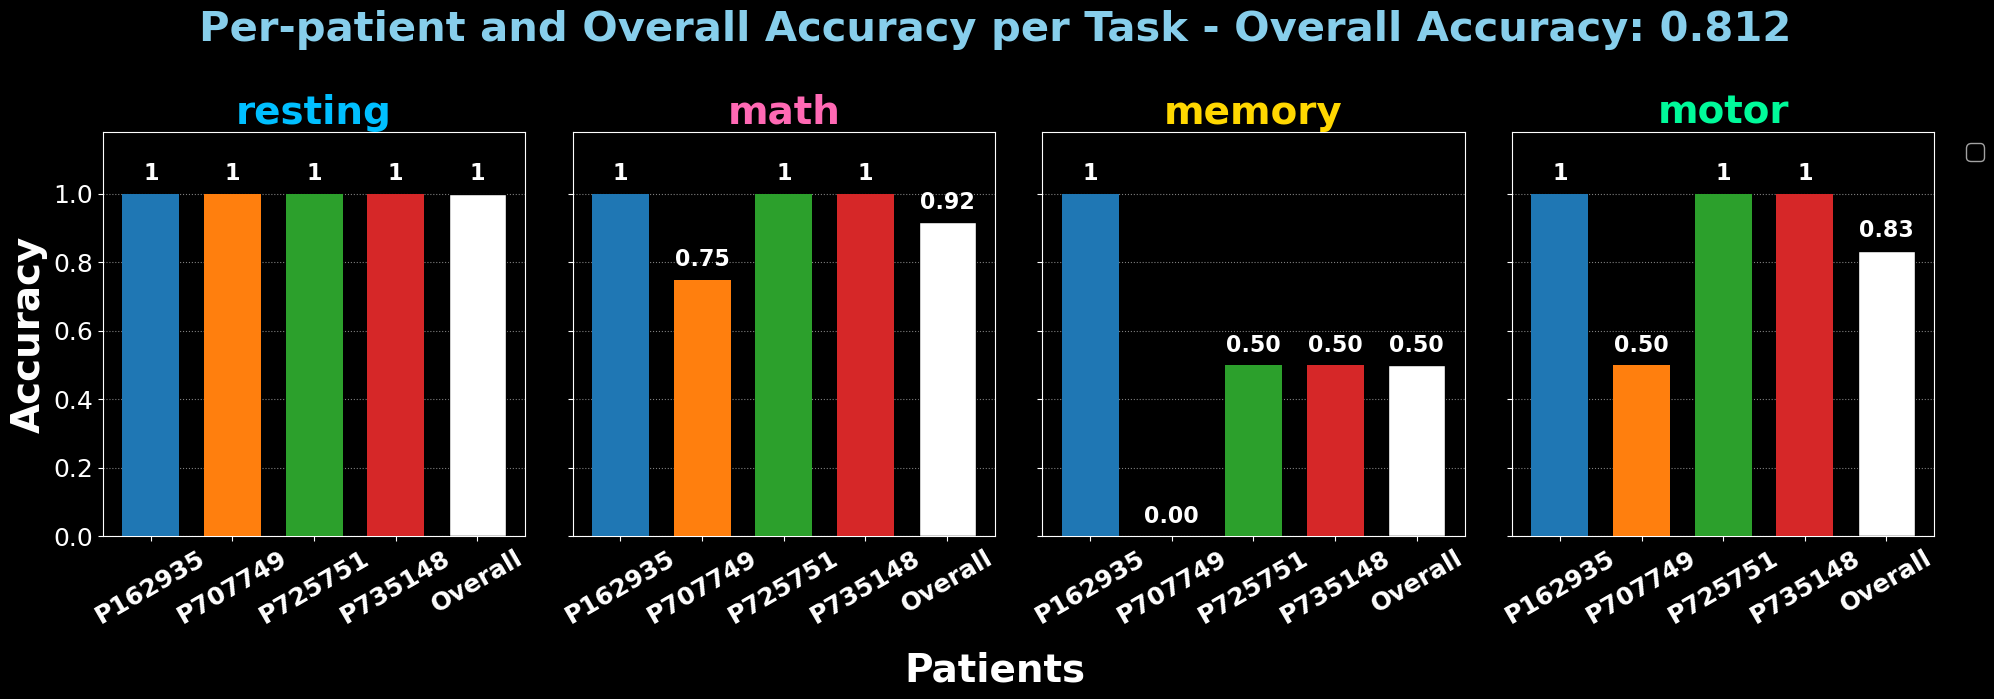

In [35]:
import importlib
importlib.reload(utils)

fig, axs, path, per_patient_acc, overall_acc_per_task = utils.plot_per_patient_accuracy_bars(
    df_test_result,
    output_dir,
    which_dataset,
    model_name,
    timestamp,
    task_names=["resting", "math", "memory", "motor"]
)

In [ ]:
import importlib
importlib.reload(utils)

utils.plot_per_patient_accuracy_heatmap(
    per_patient_acc,
    overall_acc_per_task,
    df_test_result,
    output_dir,
    which_dataset,
    model_name,
    timestamp,
    task_names=["resting", "math", "memory", "motor"]
)

In [ ]:
from IPython.display import Image, display

display(Image(filename="overfitunsurefry.webp"))

In [ ]:
print("we are done, goodbye!")